# Imports

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
omega0 = 1.0
beta = 0.2
delta = 0.1
F0 = 0.3
omega_n1 = 1.2                         # Naloga 1
w_sweep = np.linspace(0.6, 1.8, 61)    # frekvencni prelet
n_trans, n_meri = 40, 5                # st. period: prehodni pojav / merjenje

rtol, atol = 1e-8, 1e-10

# Funkcije

In [2]:
# Simbolno: harmonsko ravnovesje, x = A cos(theta), theta = w t - phi
A, w, th, phi = sp.symbols("A omega theta phi", positive=True)
w0, b, d, F = sp.symbols("omega_0 beta delta F_0", real=True)

x_h = A * sp.cos(th)
xd = -A * w * sp.sin(th)              # dx/dt
xdd = -A * w**2 * sp.cos(th)          # d2x/dt2
res = xdd + d * xd + w0**2 * x_h + b * x_h**3
vzb = F * sp.cos(th + phi)            # F0 cos(w t)

# projekcija na cos(theta) in sin(theta)
proj = lambda g, h: sp.simplify(sp.integrate(sp.expand(g * h), (th, 0, 2 * sp.pi)) / sp.pi)
eq_c = sp.Eq(proj(res, sp.cos(th)), sp.expand_trig(proj(vzb, sp.cos(th))))
eq_s = sp.Eq(proj(res, sp.sin(th)), sp.expand_trig(proj(vzb, sp.sin(th))))

# amplitudna enacba G(A^2) = F0^2
A2 = sp.symbols("A2", positive=True)
G = (A2 * ((w0**2 - w**2 + sp.Rational(3, 4) * b * A2)**2 + (d * w)**2))
dG = sp.diff(G, A2)

In [3]:
def amplitude_hb(w_os, beta=beta, delta=delta, F0=F0):
    # vse realne pozitivne resitve G(A^2) = F0^2 in njihova stabilnost (dG/dA^2 > 0)
    par = {w0: omega0, b: beta, d: delta}
    poli = sp.Poly(sp.expand(G.subs(par) - F0**2), A2)
    dG_np = sp.lambdify((A2, w), dG.subs(par), "numpy")
    tocke = []
    for wi in w_os:
        koef = [complex(c.subs(w, wi)).real for c in poli.all_coeffs()]
        for a2 in np.roots(koef):
            if abs(a2.imag) < 1e-9 and a2.real > 0:
                tocke.append((wi, np.sqrt(a2.real), dG_np(a2.real, wi) > 0))
    return np.array(tocke)

def rhs(t, y, w, beta=beta, delta=delta):
    x, v = y
    return [v, -delta * v - omega0**2 * x - beta * x**3 + F0 * np.cos(w * t)]

def ustaljeno(w, y0, beta=beta, delta=delta):
    # integracija cez n_trans + n_meri period; amplituda iz zadnjih n_meri period
    T = 2 * np.pi / w
    t_m = np.linspace(n_trans * T, (n_trans + n_meri) * T, 50 * n_meri)
    sol = solve_ivp(rhs, (0, t_m[-1]), y0, args=(w, beta, delta), t_eval=t_m, rtol=rtol, atol=atol)
    A_ust = 0.5 * (sol.y[0].max() - sol.y[0].min())
    return A_ust, sol.y[:, -1]

def prelet(w_os, beta=beta, delta=delta):
    # zadnje stanje pri w_k = zacetni pogoj pri w_{k+1}
    y, A_list = [0.0, 0.0], []
    for wi in w_os:
        A_ust, y = ustaljeno(wi, y, beta, delta)
        A_list.append(A_ust)
    return np.array(A_list)

def narisi_hb(ax, tocke, oznaka="harmonsko ravnovesje"):
    st, nst = tocke[tocke[:, 2] == 1], tocke[tocke[:, 2] == 0]
    ax.plot(st[:, 0], st[:, 1], ".", color="gray", markersize=3, label=oznaka + " (stabilno)")
    ax.plot(nst[:, 0], nst[:, 1], ".", color="red", markersize=3, label=oznaka + " (nestabilno)")

# Testno območje

In [4]:
# Pripravljalna naloga
display(sp.Eq(sp.cos(th)**3, sp.Rational(3, 4) * sp.cos(th) + sp.Rational(1, 4) * sp.cos(3 * th)))
print("omega_eff^2 = omega_0^2 + 3/4 beta A^2  (koeficient pred A cos(theta))")
display(eq_c, eq_s)
print("delta = 0:")
display(sp.Eq(sp.factor(eq_c.lhs.subs(d, 0)), eq_c.rhs))

Eq(cos(theta)**3, 3*cos(theta)/4 + cos(3*theta)/4)

omega_eff^2 = omega_0^2 + 3/4 beta A^2  (koeficient pred A cos(theta))


Eq(A*(3*A**2*beta/4 - omega**2 + omega_0**2), F_0*cos(phi))

Eq(-A*delta*omega, -F_0*sin(phi))

delta = 0:


Eq(A*(3*A**2*beta - 4*omega**2 + 4*omega_0**2)/4, F_0*cos(phi))

# Naloga 1

ustaljena amplituda pri omega = 1.2: A = 1.9230


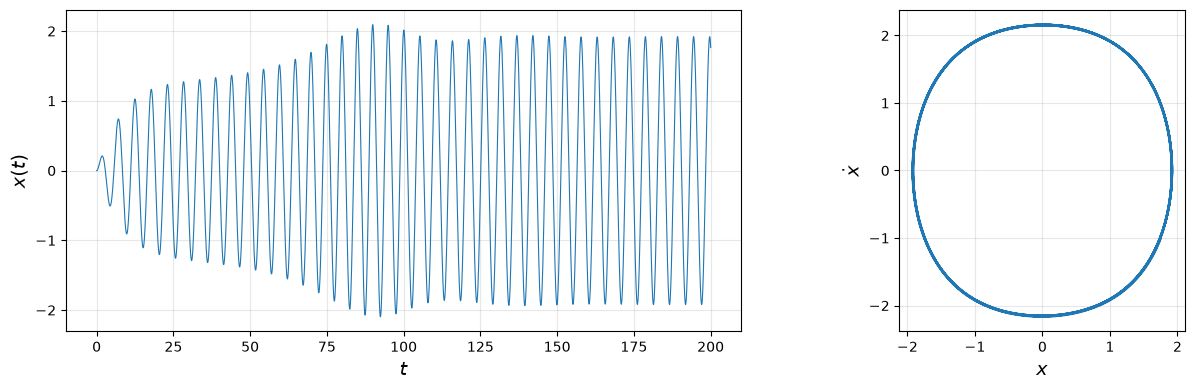

In [5]:
T1 = 2 * np.pi / omega_n1
t_ev = np.linspace(0, 200, 20001)
sol = solve_ivp(rhs, (0, 200), [0.0, 0.0], args=(omega_n1,), t_eval=t_ev, rtol=rtol, atol=atol)
zadnjih = sol.t > 200 - 10 * T1
print(f"ustaljena amplituda pri omega = {omega_n1}: A = {0.5 * np.ptp(sol.y[0][zadnjih]):.4f}")

fig = plt.figure(figsize=(14, 4))
ax = fig.add_subplot(121)
ax.plot(sol.t, sol.y[0], linewidth=0.8)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$x(t)$", fontsize=14)
ax.grid(alpha=0.3)

ax = fig.add_subplot(122)
ax.plot(sol.y[0][zadnjih], sol.y[1][zadnjih])
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel(r"$\dot{x}$", fontsize=14)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Naloga 2

preskok navzgor: med omega = 1.32 in 1.34  (A: 2.278 -> 0.389)
preskok navzdol: med omega = 1.20 in 1.18  (A: 0.856 -> 1.852)


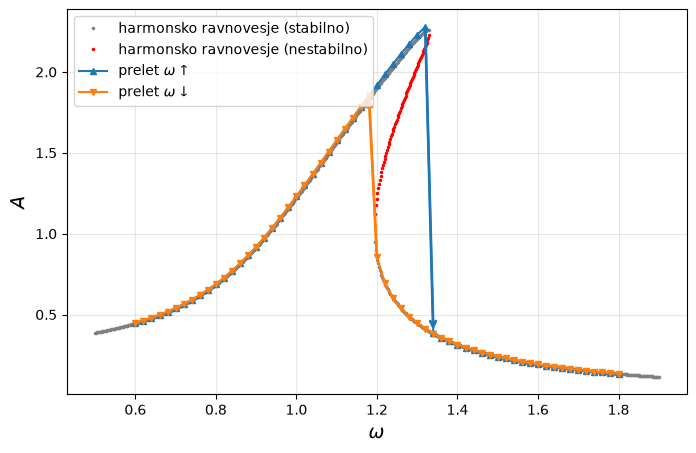

In [6]:
A_gor = prelet(w_sweep)
A_dol = prelet(w_sweep[::-1])[::-1]
hb = amplitude_hb(np.linspace(0.5, 1.9, 700))

# tocki preskoka: najvecja sprememba amplitude med sosednjima frekvencama
i_gor = np.argmax(np.abs(np.diff(A_gor)))
i_dol = np.argmax(np.abs(np.diff(A_dol)))
print(f"preskok navzgor: med omega = {w_sweep[i_gor]:.2f} in {w_sweep[i_gor + 1]:.2f}  (A: {A_gor[i_gor]:.3f} -> {A_gor[i_gor + 1]:.3f})")
print(f"preskok navzdol: med omega = {w_sweep[i_dol + 1]:.2f} in {w_sweep[i_dol]:.2f}  (A: {A_dol[i_dol + 1]:.3f} -> {A_dol[i_dol]:.3f})")

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111)
narisi_hb(ax, hb)
ax.plot(w_sweep, A_gor, "^-", color="C0", markersize=4, label=r"prelet $\omega \uparrow$")
ax.plot(w_sweep, A_dol, "v-", color="C1", markersize=4, label=r"prelet $\omega \downarrow$")
ax.annotate("", xy=(w_sweep[i_gor + 1], A_gor[i_gor + 1]), xytext=(w_sweep[i_gor], A_gor[i_gor]),
            arrowprops=dict(arrowstyle="->", color="C0", lw=2))
ax.annotate("", xy=(w_sweep[i_dol], A_dol[i_dol]), xytext=(w_sweep[i_dol + 1], A_dol[i_dol + 1]),
            arrowprops=dict(arrowstyle="->", color="C1", lw=2))
ax.set_xlabel(r"$\omega$", fontsize=14)
ax.set_ylabel("$A$", fontsize=14)
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.show()

# Naloga 3

linearni:   vrh pri omega = 1.00,  A_max = 3.000
nelinearni: vrh pri omega = 1.32,  A_max = 2.278


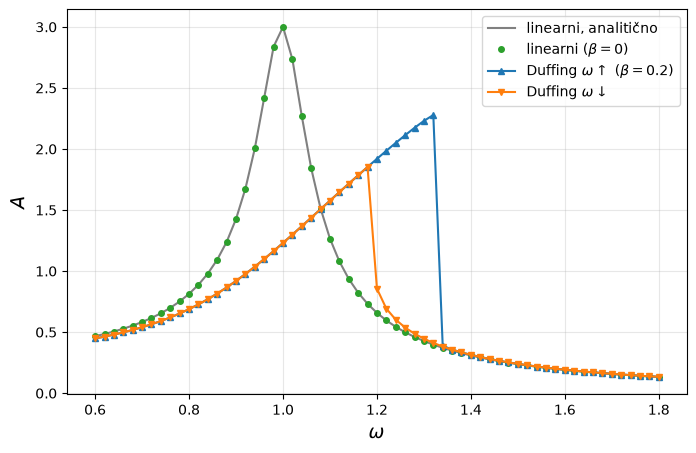

In [7]:
A_lin = prelet(w_sweep, beta=0.0)
A_lin_an = F0 / np.sqrt((omega0**2 - w_sweep**2)**2 + (delta * w_sweep)**2)
print(f"linearni:   vrh pri omega = {w_sweep[np.argmax(A_lin)]:.2f},  A_max = {A_lin.max():.3f}")
print(f"nelinearni: vrh pri omega = {w_sweep[np.argmax(A_gor)]:.2f},  A_max = {A_gor.max():.3f}")

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111)
ax.plot(w_sweep, A_lin_an, "-", color="gray", label=r"linearni, analitično")
ax.plot(w_sweep, A_lin, "o", color="C2", markersize=4, label=r"linearni ($\beta = 0$)")
ax.plot(w_sweep, A_gor, "^-", color="C0", markersize=4, label=rf"Duffing $\omega \uparrow$ ($\beta = {beta}$)")
ax.plot(w_sweep, A_dol, "v-", color="C1", markersize=4, label=r"Duffing $\omega \downarrow$")
ax.set_xlabel(r"$\omega$", fontsize=14)
ax.set_ylabel("$A$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 1

omega = 1.2490701001430615: srednja veja A = 1.7055
s < 1.02 -> spodnja veja,  s >= 1.02 -> zgornja veja


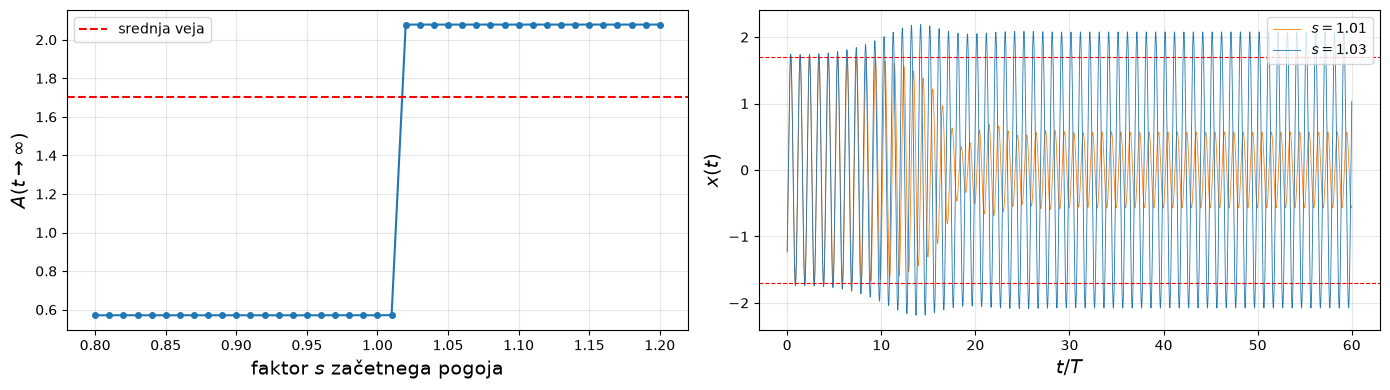

In [8]:
# Zacetni pogoj na srednji (nestabilni) veji -> sistem jo zapusti
nst = hb[hb[:, 2] == 0]
w_t, A_s = nst[np.argmin(np.abs(nst[:, 0] - 1.25)), :2]
Om = omega0**2 - w_t**2 + 0.75 * beta * A_s**2
phi_s = np.arctan2(delta * w_t * A_s, Om * A_s)
y0_s = [A_s * np.cos(phi_s), A_s * w_t * np.sin(phi_s)]
print(f"omega = {w_t}: srednja veja A = {A_s:.4f}")

T = 2 * np.pi / w_t

# skaliramo zacetni pogoj s faktorjem s in pogledamo, na kateri veji sistem konca
s_os = np.linspace(0.8, 1.2, 41)
A_konc = np.array([ustaljeno(w_t, [s * y0_s[0], s * y0_s[1]])[0] for s in s_os])
s_meja = s_os[np.argmax(A_konc > A_s)]
print(f"s < {s_meja:.2f} -> spodnja veja,  s >= {s_meja:.2f} -> zgornja veja")

t_ev = np.linspace(0, 60 * T, 30000)
fig = plt.figure(figsize=(14, 4))
ax = fig.add_subplot(121)
ax.plot(s_os, A_konc, "o-", markersize=4)
ax.axhline(A_s, color="red", linestyle="--", label="srednja veja")
ax.set_xlabel("faktor $s$ začetnega pogoja", fontsize=14)
ax.set_ylabel(r"$A(t \to \infty)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)

ax = fig.add_subplot(122)
for s, c in [(s_meja - 0.01, "C1"), (s_meja + 0.01, "C0")]:
    sol = solve_ivp(rhs, (0, t_ev[-1]), [s * y0_s[0], s * y0_s[1]], args=(w_t,), t_eval=t_ev, rtol=rtol, atol=atol)
    ax.plot(sol.t / T, sol.y[0], color=c, linewidth=0.6, label=f"$s = {s:.2f}$")
for sg in (1, -1):
    ax.axhline(sg * A_s, color="red", linestyle="--", linewidth=0.8)
ax.set_xlabel("$t/T$", fontsize=14)
ax.set_ylabel("$x(t)$", fontsize=14)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Razmislek 2

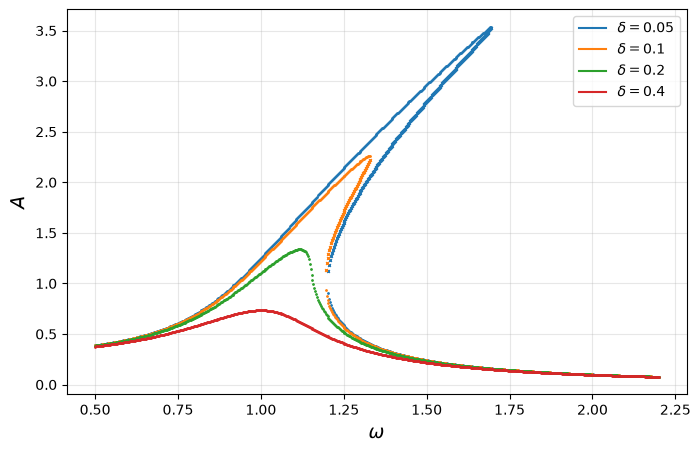

histereza izgine pri delta > 0.17  (F0 = 0.3, beta = 0.2)


In [9]:
# Vpliv dusenja na resonancno krivuljo in obstoj vecvrednostnega obmocja
w_os = np.linspace(0.5, 2.2, 600)

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111)
for dd, c in zip([0.05, 0.1, 0.2, 0.4], ["C0", "C1", "C2", "C3"]):
    tocke = amplitude_hb(w_os, delta=dd)
    st, nst = tocke[tocke[:, 2] == 1], tocke[tocke[:, 2] == 0]
    ax.plot(st[:, 0], st[:, 1], ".", color=c, markersize=2)
    ax.plot(nst[:, 0], nst[:, 1], "x", color=c, markersize=2)
    ax.plot([], [], "-", color=c, label=rf"$\delta = {dd}$")
ax.set_xlabel(r"$\omega$", fontsize=14)
ax.set_ylabel("$A$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# kriticno dusenje: najvecje delta, pri katerem se pojavijo nestabilne (srednje) resitve
d_os = np.linspace(0.05, 0.6, 56)
ima_hist = [np.any(amplitude_hb(np.linspace(0.8, 2.5, 300), delta=dd)[:, 2] == 0) for dd in d_os]
d_c = d_os[np.where(ima_hist)[0][-1]]
print(f"histereza izgine pri delta > {d_c:.2f}  (F0 = {F0}, beta = {beta})")